In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/customers.csv', encoding='utf-8-sig')

In [3]:
df.shape

In [4]:
df.head()

    Customer_ID  Customer_Name  Gender  ...  Customer_Tier Total_Orders Total_Spent
0  CUST00000001  Akash Agarwal    male  ...           Gold            5    40098.48
1  CUST00000002  Farhan Rahman    male  ...       Platinum            8    63676.24
2  CUST00000003   Suresh Kumar    male  ...         Silver            0        0.00
3  CUST00000004  Aditya Pandey    male  ...       Platinum            5   288324.84
4  CUST00000005      Hina Khan  female  ...       Platinum            4    69265.75

[5 rows x 13 columns]

In [5]:
df.tail()

        Customer_ID  Customer_Name  ... Total_Orders  Total_Spent
39995  CUST00039996    Swati Joshi  ...            4    137030.99
39996  CUST00039997   Nikhil Patel  ...            8    193564.72
39997  CUST00039998    Akash Yadav  ...            6    191316.63
39998  CUST00039999  Salman Ansari  ...            2      6482.53
39999  CUST00040000    Ahmed Ahmed  ...            8    216922.80

[5 rows x 13 columns]

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Customer_ID        40000 non-null  str    
 1   Customer_Name      40000 non-null  str    
 2   Gender             40000 non-null  str    
 3   Age                40000 non-null  int64  
 4   Age_Group          40000 non-null  str    
 5   Date_of_Birth      40000 non-null  str    
 6   City               40000 non-null  str    
 7   State              40000 non-null  str    
 8   Pincode            40000 non-null  int64  
 9   Registration_Date  40000 non-null  str    
 10  Customer_Tier      40000 non-null  str    
 11  Total_Orders       40000 non-null  int64  
 12  Total_Spent        40000 non-null  float64
dtypes: float64(1), int64(3), str(9)
memory usage: 4.0 MB


In [7]:
# Email/Phone are removed in the shared CSV already; errors='ignore' keeps this safe if you use the raw file
df.drop(['Email','Phone'], axis=1, inplace=True, errors='ignore')

In [8]:
df.columns

Index(['Customer_ID', 'Customer_Name', 'Gender', 'Age', 'Age_Group',
       'Date_of_Birth', 'City', 'State', 'Pincode', 'Registration_Date',
       'Customer_Tier', 'Total_Orders', 'Total_Spent'],
      dtype='str')

In [9]:
pd.isnull(df).sum()

Customer_ID          0
Customer_Name        0
Gender               0
Age                  0
Age_Group            0
Date_of_Birth        0
City                 0
State                0
Pincode              0
Registration_Date    0
Customer_Tier        0
Total_Orders         0
Total_Spent          0
dtype: int64

In [10]:
df['Date_of_Birth'] = pd.to_datetime(df['Date_of_Birth'])
df['Registration_Date'] = pd.to_datetime(df['Registration_Date'])
df['Pincode'] = df['Pincode'].astype('str')

In [11]:
df.dtypes

Customer_ID                     str
Customer_Name                   str
Gender                          str
Age                           int64
Age_Group                       str
Date_of_Birth        datetime64[us]
City                            str
State                           str
Pincode                         str
Registration_Date    datetime64[us]
Customer_Tier                   str
Total_Orders                  int64
Total_Spent                 float64
dtype: object

## Exploratory Data Analysis

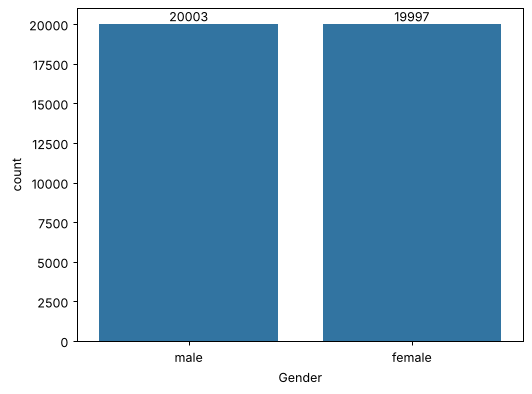

In [12]:
ax = sns.countplot(data = df, x = 'Gender')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

*we find out that total number of male and female in this data is almost equal here*

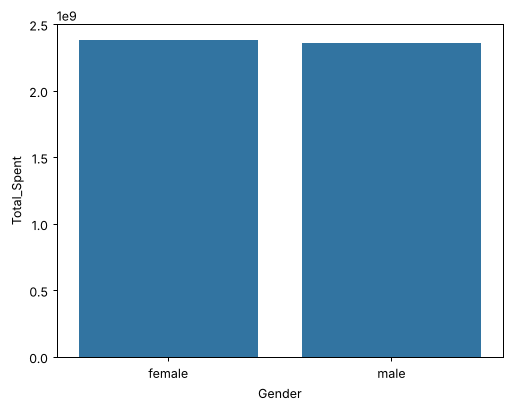

In [13]:
Totalspent_by_Gender = df.groupby(['Gender'],as_index = False)['Total_Spent'].sum().sort_values(by = 'Total_Spent', ascending = False)

sns.barplot(data = Totalspent_by_Gender, x = 'Gender',y = 'Total_Spent')
plt.show()

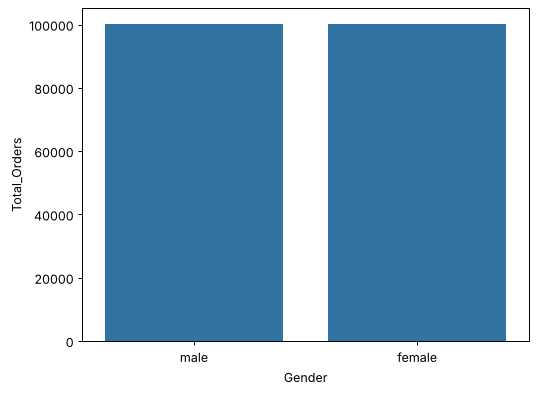

In [14]:
Totalorders_by_Gender = df.groupby(['Gender'],as_index = False)['Total_Orders'].sum().sort_values(by = 'Total_Orders', ascending = False)

sns.barplot(data = Totalorders_by_Gender, x = 'Gender',y = 'Total_Orders')
plt.show()

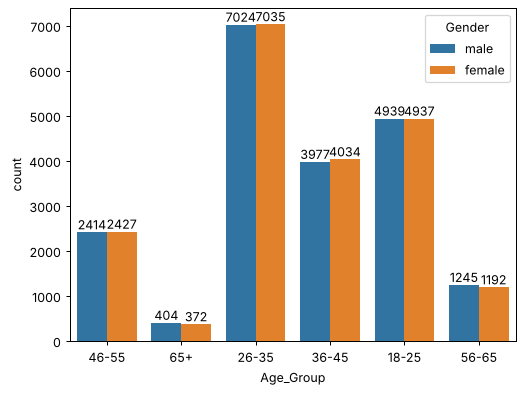

In [15]:
ax = sns.countplot(data = df, x = 'Age_Group', hue = 'Gender')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

*26-35 is the largest age group by customer count (14,059). The next chart checks whether it also leads on spend.*

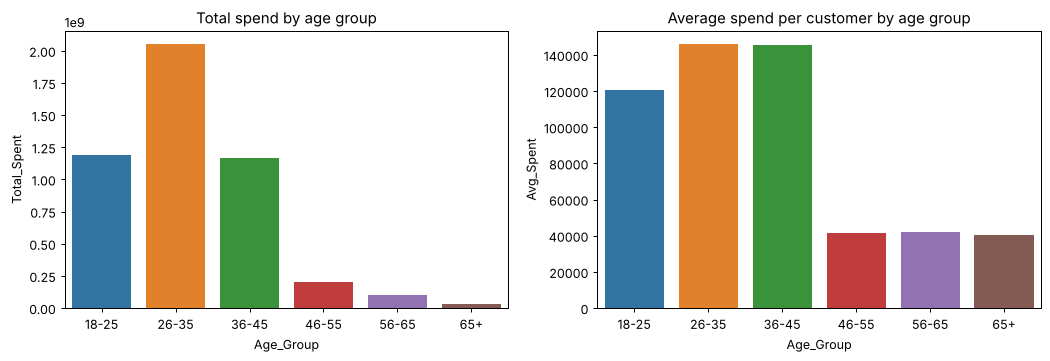

In [16]:
age_spend = df.groupby('Age_Group', as_index=False).agg(Total_Spent=('Total_Spent','sum'), Avg_Spent=('Total_Spent','mean'))

fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.barplot(data=age_spend, x='Age_Group', y='Total_Spent', hue='Age_Group', legend=False, ax=ax[0])
ax[0].set_title('Total spend by age group')
sns.barplot(data=age_spend, x='Age_Group', y='Avg_Spent', hue='Age_Group', legend=False, ax=ax[1])
ax[1].set_title('Average spend per customer by age group')
plt.show()

*26-35 has the highest total spend (~₹2.05B). Average spend per customer is about the same for 26-35 and 36-45 (~₹146K), and then drops sharply to ~₹41K for 46+. So the younger groups drive revenue.*

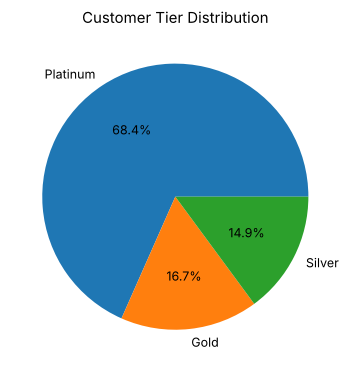

In [17]:
df['Customer_Tier'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Customer Tier Distribution'
)

plt.show()

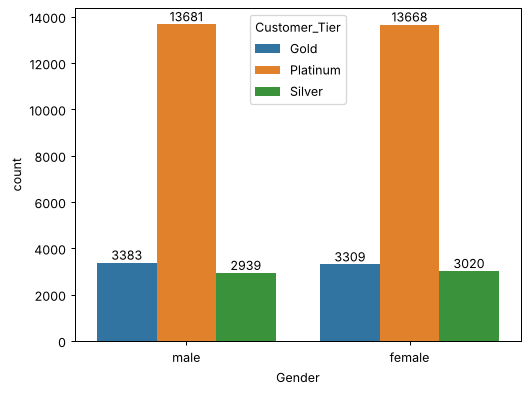

In [18]:
ax = sns.countplot(data = df, x = 'Gender', hue = 'Customer_Tier')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

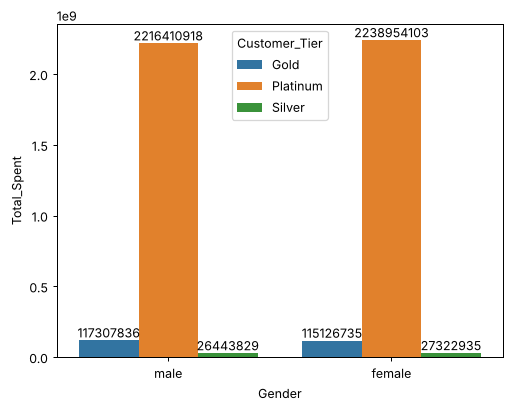

In [19]:
ax = sns.barplot(data = df, x = 'Gender', y = 'Total_Spent', hue = 'Customer_Tier',
                 estimator='sum', errorbar=None)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')
plt.show()

*Male and female customers aged 26-35 in the Platinum tier contribute the highest total spend, making them the core revenue segment.*

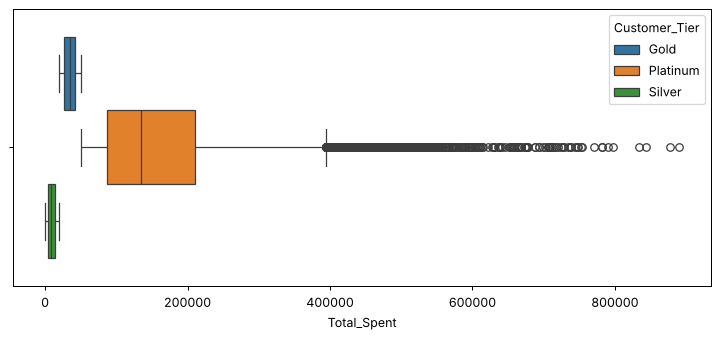

In [20]:
#outlier check
plt.figure(figsize=(10, 4))
sns.boxplot(data = df,x = 'Total_Spent', hue = 'Customer_Tier')
plt.show()

In [21]:
Q1, Q3 = df['Total_Spent'].quantile([0.25, 0.75])
upper_fence = Q3 + 1.5*(Q3 - Q1)
outliers = df[df['Total_Spent'] > upper_fence]
print(len(outliers), 'rows flagged as outliers')
print(outliers['Customer_Tier'].value_counts())

1319 rows flagged as outliers
Customer_Tier
Platinum    1319
Name: count, dtype: int64


*Statistical outliers in Total_Spent (1,319 rows, ~3.3% of customers) are entirely Platinum-tier customers — reflecting genuine high-value spenders rather than data errors, so they were retained rather than removed.*

In [22]:
zero_spend = df[df['Total_Spent'] == 0]
print(len(zero_spend))
print(zero_spend['Customer_Tier'].value_counts())


274
Customer_Tier
Silver    274
Name: count, dtype: int64


*274 customers have ₹0 total spend, all from the Silver tier, likely customers who registered but never made a purchase, worth flagging separately from active low-spenders.*

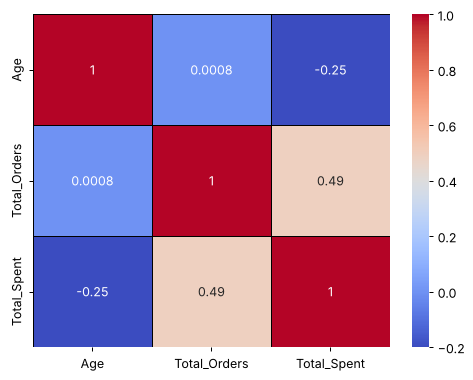

In [23]:
columns = ["Age","Total_Orders","Total_Spent"]
df[columns].corr()


sns.heatmap(data = df[columns].corr(), annot = True,cmap = "coolwarm",vmin = -0.2,linewidths = 0.5,linecolor = "Black")

*Total_Orders and Total_Spent show a moderate positive correlation (0.49), while Age shows a weak negative correlation with spend (-0.25) and virtually no relationship with order count (0.0008) — suggesting spend is driven more by purchase behavior than by customer age.*

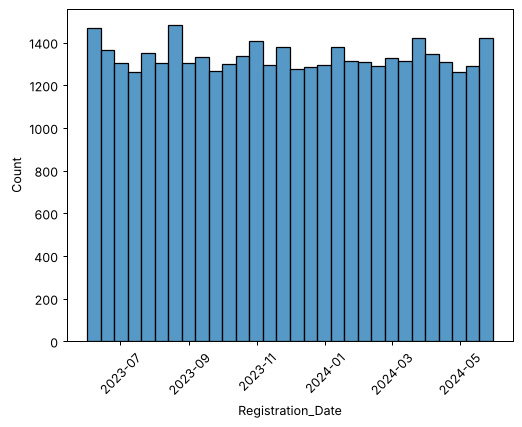

In [24]:
sns.histplot(data=df, x='Registration_Date', bins=30)
plt.xticks(rotation=45)
plt.show()

*Customer registrations are steady across the period (June 2023 to June 2024), with no clear growth trend or seasonality.*

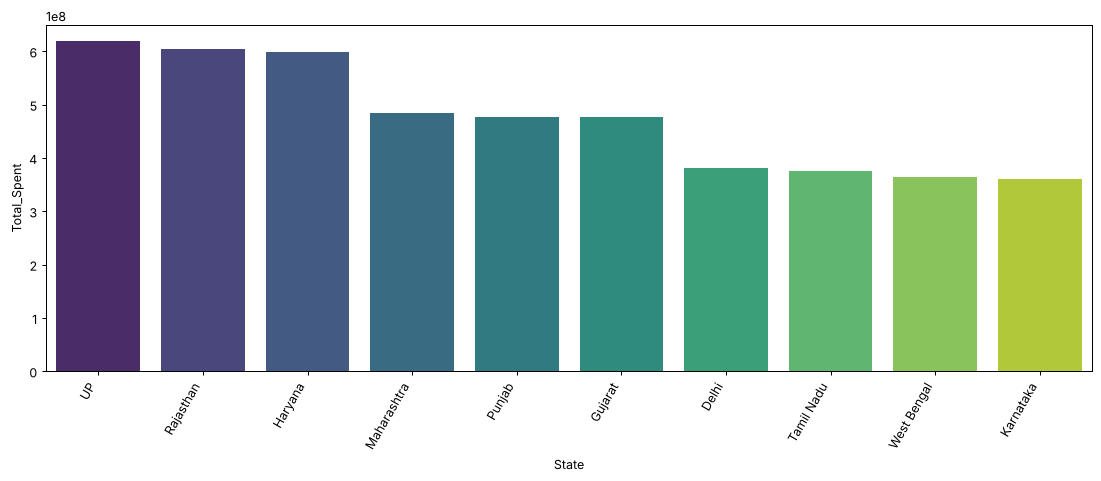

In [25]:
topspentbystates = df.groupby(['State'], as_index=False)['Total_Spent'].sum().sort_values(by='Total_Spent', ascending=False)

plt.figure(figsize=(15,5))
sns.barplot(data=topspentbystates, x='State', y='Total_Spent', hue='State', palette='viridis', legend=False)
plt.xticks(rotation=60, ha='right')
plt.show()

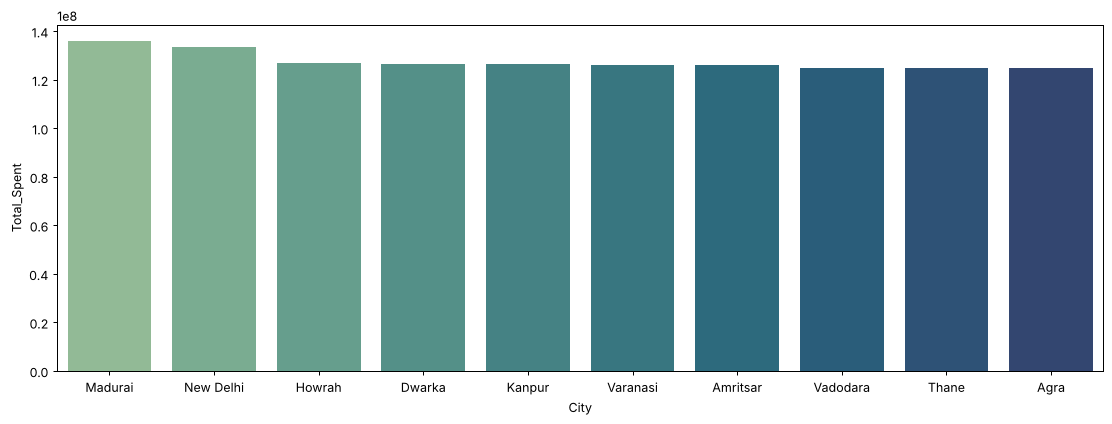

In [26]:
topspentbycities = df.groupby(['City'], as_index=False)['Total_Spent'].sum().sort_values(by='Total_Spent', ascending=False).head(10)

plt.figure(figsize=(15,5))
sns.barplot(data=topspentbycities, x='City', y='Total_Spent', hue='City', palette='crest', legend=False)
plt.show()

*Madurai (Tamil Nadu) is the top city by total spend (~₹136M), but Tamil Nadu ranks only 8th among states. Spend is spread across many cities, so the top city does not come from the top state.*

Gender
female    9
male      6
Name: count, dtype: int64


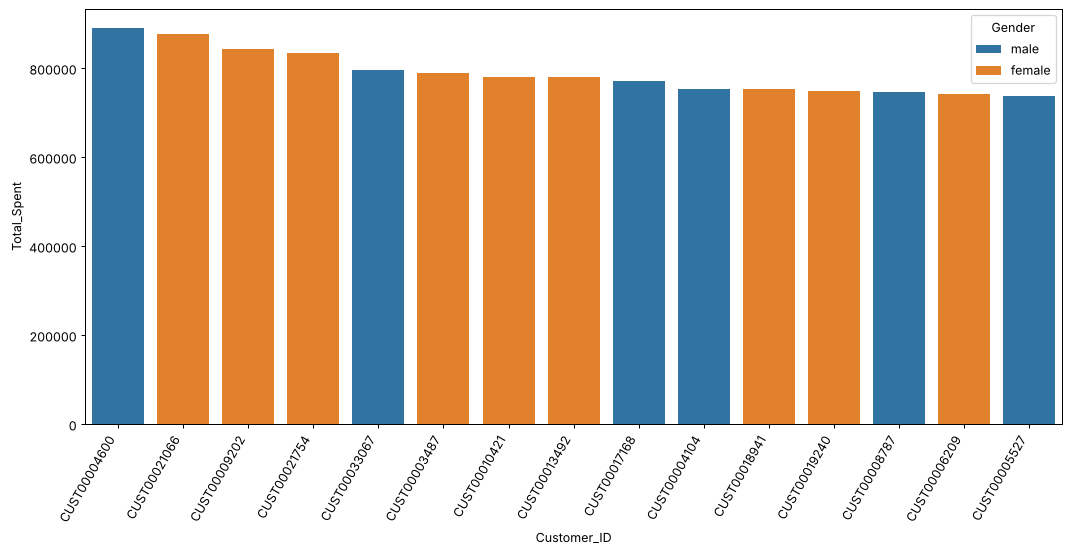

In [27]:
# Group by Customer_ID, not Customer_Name: names are not unique (only 927 distinct names across 40,000 customers)
top15customers = (df.groupby(['Customer_ID','Gender'], as_index=False)['Total_Spent'].sum()
                    .sort_values(by='Total_Spent', ascending=False).head(15))

plt.figure(figsize=(14,6))
sns.barplot(data=top15customers, x='Customer_ID', y='Total_Spent', hue='Gender')
plt.xticks(rotation=60, ha='right')
plt.show()

print(top15customers['Gender'].value_counts())

*The top 15 individual customers (by Customer_ID) split 9 female / 6 male, so there is no strong gender skew, which matches the overall near-equal spend. Note: I group by Customer_ID because Customer_Name is not unique (927 distinct names for 40,000 customers), so grouping by name would merge different people.*

## Conclusion:

*Male and female customers contribute almost equally to total spend, so gender isn't a differentiator. Platinum is the top-spending tier, and customers aged 26-35 lead all age groups in revenue contribution. Uttar Pradesh, Rajasthan and Haryana lead all other states in total spend, making them the key regions.* Spend per customer drops sharply after age 45 (about ₹41K vs ₹146K for 26-45).